# Previsão de Temperatura com LSTM — Jena Climate Dataset

**Curso:** Ciência da Computação  
**Disciplina:** Machine Learning e Otimização

**Turma:** CC7 - NA

**Alunos:** Lucas Gama de Souza e Felipe Daniel Freitas de Souza
**Professora:** Polyana Santos Fonseca Nascimento

---
## Declaração de Uso de IA Generativa

Em conformidade com os princípios institucionais de transparência no uso de Inteligencia Artificial Generativa, declaramos:

| Item | Descricao |
|------|-----------|
| **Uso de IA Generativa** | Sim |
| **Ferramenta utilizada** | Claude (Anthropic) |
| **Finalidade do uso** | Auxilio na estruturação do notebook, sugestão de código e organização |
| **Extensao da contribuicao** |  Análises e interpretações foram realizadas pelos autores |
| **Medidas de validacao** | Todo o codigo foi revisado, executado celula a celula e os resultados foram interpretados e validados pelos autores antes da entrega |

---
## Instalações e Importações

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, RMSprop, SGD

print('TensorFlow:', tf.__version__)
print('NumPy     :', np.__version__)
print('Pandas    :', pd.__version__)
print('Matplotlib:', matplotlib.__version__)

TensorFlow: 2.20.0
NumPy     : 2.0.2
Pandas    : 2.2.2
Matplotlib: 3.10.0


---
## Escolha e Preparação do Dataset

### Informações do Dataset

| Item | Descricao |
|------|-----------|
| **Nome** | Jena Climate Dataset |
| **Fonte** | TensorFlow / Kaggle — [mnassrib/jena-climate](https://www.kaggle.com/datasets/mnassrib/jena-climate) |
| **Problema** | Previsão multivariada de temperatura com base em variáveis meteorológicas |
| **Variáveis de entrada** | Pressão atmosferica, temperatura do ponto de orvalho, umidade relativa, pressão de vapor, velocidade do vento, densidade do ar |
| **Variável alvo** | `T (degC)` — temperatura em graus Celsius |
| **Justificativa** | Dataset real e amplamente usado em benchmarks de LSTM. Possui forte sazonalidade diária e anual, e é multivariado, permitindo explorar correlações entre variáveis meteorológicas. |

In [2]:
# Download automatico do dataset via URL publica do TensorFlow
import urllib.request
import zipfile
import os

csv_name = 'jena_climate_2009_2016.csv'
url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'

if not os.path.exists(csv_name):
    print('Baixando dataset...')
    urllib.request.urlretrieve(url, 'jena_climate.zip')
    with zipfile.ZipFile('jena_climate.zip', 'r') as z:
        z.extractall('.')
    print('Concluido.')
else:
    print('Dataset ja disponivel.')

Baixando dataset...
Concluido.


In [3]:
# Carregamento
df = pd.read_csv('jena_climate_2009_2016.csv')
print('Shape:', df.shape)
df.head()

Shape: (420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


In [4]:
# Informacoes gerais e valores ausentes
print('Informacoes do DataFrame:')
df.info()
print()
missing = df.isnull().sum()
print('Valores ausentes por coluna:')
print(missing[missing > 0] if missing.sum() > 0 else 'Nenhum valor ausente encontrado.')

Informacoes do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420551 entries, 0 to 420550
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date Time        420551 non-null  object 
 1   p (mbar)         420551 non-null  float64
 2   T (degC)         420551 non-null  float64
 3   Tpot (K)         420551 non-null  float64
 4   Tdew (degC)      420551 non-null  float64
 5   rh (%)           420551 non-null  float64
 6   VPmax (mbar)     420551 non-null  float64
 7   VPact (mbar)     420551 non-null  float64
 8   VPdef (mbar)     420551 non-null  float64
 9   sh (g/kg)        420551 non-null  float64
 10  H2OC (mmol/mol)  420551 non-null  float64
 11  rho (g/m**3)     420551 non-null  float64
 12  wv (m/s)         420551 non-null  float64
 13  max. wv (m/s)    420551 non-null  float64
 14  wd (deg)         420551 non-null  float64
dtypes: float64(14), object(1)
memory usage: 48.1+ MB

Valores a

In [5]:
# Conversão da coluna de data para datetime e definição como índice
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df = df.set_index('Date Time')

print('Periodo coberto:')
print('  Inicio:', df.index.min())
print('  Fim   :', df.index.max())
print('  Registros:', len(df))
print('  Frequencia: 10 minutos')

Periodo coberto:
  Inicio: 2009-01-01 00:10:00
  Fim   : 2017-01-01 00:00:00
  Registros: 420551
  Frequencia: 10 minutos


### Visualização Inicial da Serie Temporal

A seguir, visualizamos a variavel alvo (`T (degC)`) em três escalas de tempo: a serie completa, um ano isolado e uma semana. Isso permite identificar tanto a sazonalidade anual quanto o ciclo diario de temperatura.

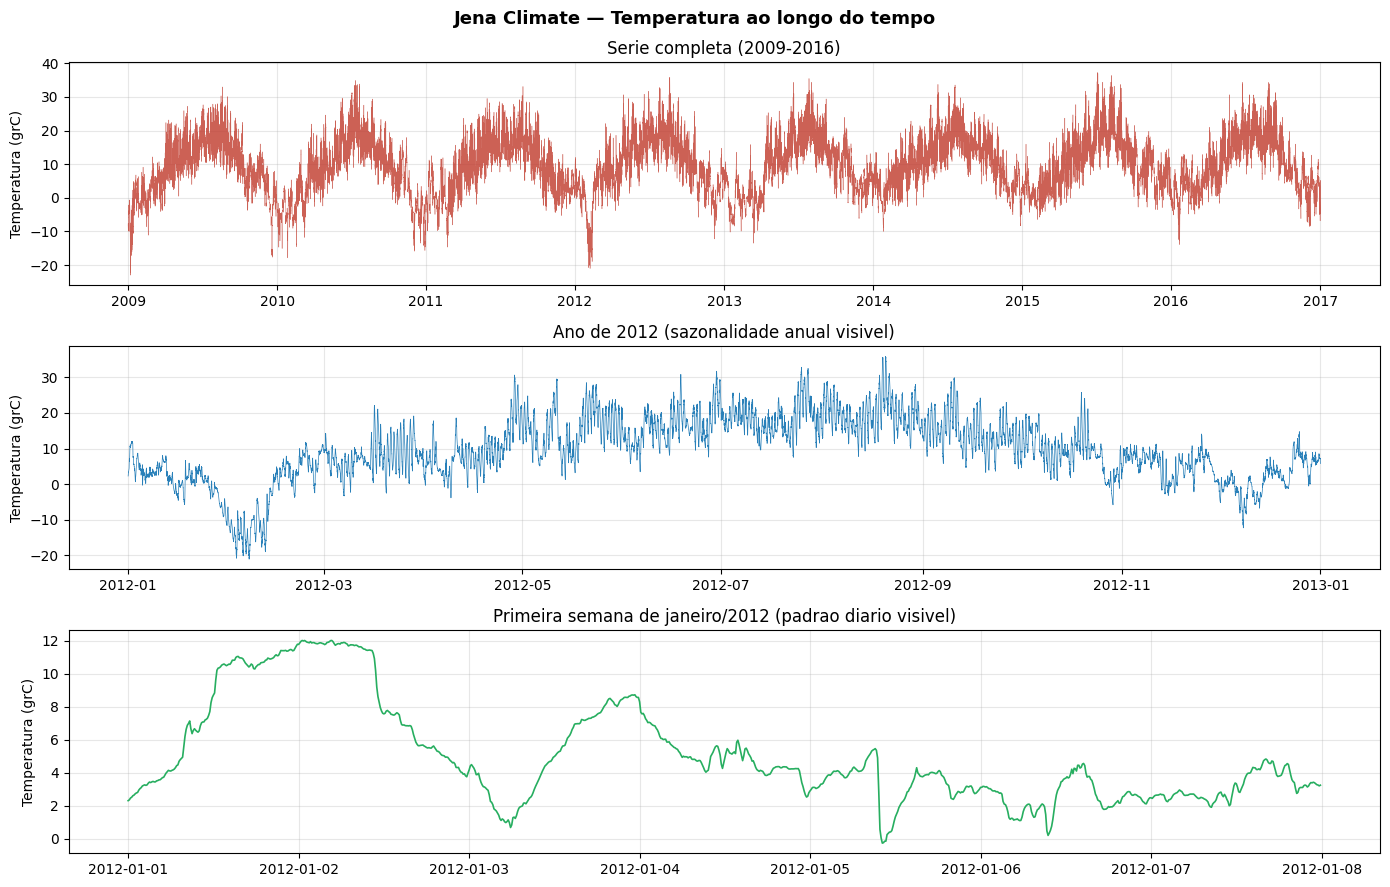

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
fig.suptitle('Jena Climate — Temperatura ao longo do tempo', fontsize=13, fontweight='bold')

# Serie completa
axes[0].plot(df.index, df['T (degC)'].values, color='#c0392b', linewidth=0.3, alpha=0.8)
axes[0].set_title('Serie completa (2009-2016)')
axes[0].set_ylabel('Temperatura (grC)')
axes[0].grid(True, alpha=0.3)

# Ano de 2012
mask_year = (df.index.year == 2012)
axes[1].plot(df.index[mask_year], df['T (degC)'].values[mask_year],
             color='#2980b9', linewidth=0.5)
axes[1].set_title('Ano de 2012 (sazonalidade anual visivel)')
axes[1].set_ylabel('Temperatura (grC)')
axes[1].grid(True, alpha=0.3)

# Primeira semana de janeiro de 2012
mask_week = (df.index >= '2012-01-01') & (df.index < '2012-01-08')
axes[2].plot(df.index[mask_week], df['T (degC)'].values[mask_week],
             color='#27ae60', linewidth=1.2)
axes[2].set_title('Primeira semana de janeiro/2012 (padrao diario visivel)')
axes[2].set_ylabel('Temperatura (grC)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Estatisticas descritivas
df.describe().round(2)

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
count,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00,420551.00
mean,989.21,9.45,283.49,4.96,76.01,13.58,9.53,4.04,6.02,9.64,1216.06,1.70,3.06,174.74
std,8.36,8.42,8.50,6.73,16.48,7.74,4.18,4.90,2.66,4.24,39.98,65.45,69.02,86.68
min,913.60,-23.01,250.60,-25.01,12.95,0.95,0.79,0.00,0.50,0.80,1059.45,-9999.00,-9999.00,0.00
25%,984.20,3.36,277.43,0.24,65.21,7.78,6.21,0.87,3.92,6.29,1187.49,0.99,1.76,124.90
50%,989.58,9.42,283.47,5.22,79.30,11.82,8.86,2.19,5.59,8.96,1213.79,1.76,2.96,198.10
75%,994.72,15.47,289.53,10.07,89.40,17.60,12.35,5.30,7.80,12.49,1242.77,2.86,4.74,234.10
max,1015.35,37.28,311.34,23.11,100.00,63.77,28.32,46.01,18.13,28.82,1393.54,28.49,23.50,360.00


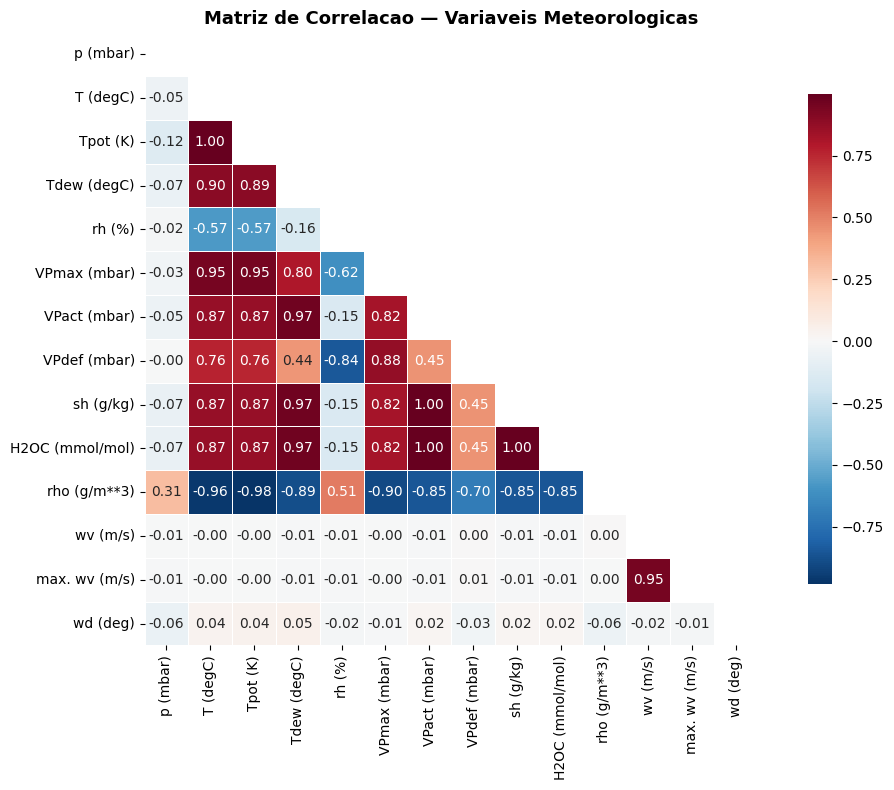

In [8]:
# Matriz de correlação entre variaveis
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Matriz de Correlacao — Variaveis Meteorologicas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Pré-processamento

### Reamostragem e Seleção de Variáveis

O dataset original possui registros a cada 10 minutos. Realizamos uma **reamostragem horaria** (media) para reduzir o volume de dados e focar em padroes de maior escala. As variaveis foram selecionadas com base na correlação com a temperatura alvo e na relevância meteorológica.

In [9]:
# Reamostragem horaria
df_hourly = df.resample('1h').mean(numeric_only=True)
print('Registros apos reamostragem horaria:', len(df_hourly))

# Variaveis selecionadas
features = ['p (mbar)', 'T (degC)', 'Tdew (degC)', 'rh (%)',
            'VPact (mbar)', 'wv (m/s)', 'rho (g/m**3)']
target = 'T (degC)'

df_model = df_hourly[features].copy()

# Tratamento de eventuais valores ausentes com interpolação linear
df_model = df_model.interpolate(method='linear')
print('Valores ausentes apos interpolacao:', df_model.isnull().sum().sum())
print('Variaveis de entrada:', features)
print('Variavel alvo       :', target)
df_model.head()

Registros apos reamostragem horaria: 70129
Valores ausentes apos interpolacao: 0
Variaveis de entrada: ['p (mbar)', 'T (degC)', 'Tdew (degC)', 'rh (%)', 'VPact (mbar)', 'wv (m/s)', 'rho (g/m**3)']
Variavel alvo       : T (degC)


,p (mbar),T (degC),Tdew (degC),rh (%),VPact (mbar),wv (m/s),rho (g/m**3)
Date Time,,,,,,,
2009-01-01 00:00:00,996.528000,-8.304000,-9.120000,93.780000,3.058000,0.520000,1309.196000
2009-01-01 01:00:00,996.525000,-8.065000,-8.861667,93.933333,3.121667,0.316667,1307.981667
2009-01-01 02:00:00,996.745000,-8.763333,-9.610000,93.533333,2.940000,0.248333,1311.816667
2009-01-01 03:00:00,996.986667,-8.896667,-9.786667,93.200000,2.898333,0.176667,1312.813333
2009-01-01 04:00:00,997.158333,-9.348333,-10.345000,92.383333,2.775000,0.290000,1315.355000


### Separação Treino e Teste

A separação respeita a ordem temporal dos dados: os primeiros 80% dos registros são usados para treino e os ultimos 20% para teste. Isso evita vazamento de informações futuras para o modelo.

In [10]:
n = len(df_model)
split = int(n * 0.80)

train_data = df_model.iloc[:split]
test_data  = df_model.iloc[split:]

print('Total de registros:', n)
print('Treino :', len(train_data), '({:.1f}%)'.format(len(train_data) / n * 100))
print('Teste  :', len(test_data),  '({:.1f}%)'.format(len(test_data)  / n * 100))
print()
print('Treino:', train_data.index[0], '->', train_data.index[-1])
print('Teste :', test_data.index[0],  '->', test_data.index[-1])

Total de registros: 70129
Treino : 56103 (80.0%)
Teste  : 14026 (20.0%)

Treino: 2009-01-01 00:00:00 -> 2015-05-27 14:00:00
Teste : 2015-05-27 15:00:00 -> 2017-01-01 00:00:00


### Normalização

Aplicamos o `MinMaxScaler` no intervalo [0, 1]. O scaler é ajustado **apenas no conjunto de treino** para evitar data leakage, e aplicado tanto no treino quanto no teste.

In [11]:
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train_data.values)
test_scaled  = scaler.transform(test_data.values)

target_idx = features.index(target)
n_features = len(features)

print('Normalizacao aplicada com sucesso.')
print('Indice da variavel alvo ("%s"): %d' % (target, target_idx))

Normalizacao aplicada com sucesso.
Indice da variavel alvo ("T (degC)"): 1


### Criação de Janelas Temporais

A LSTM recebe como entrada uma sequência de passos de tempo passados (janela temporal) e aprende a prever o próximo valor. Utilizamos **24 horas** como janela padrão no modelo base, capturando um ciclo diário completo.

In [12]:
def create_sequences(data, seq_length, target_idx):
    """
    Cria janelas temporais para a LSTM.

    Parametros
    ----------
    data       : array normalizado (n_samples, n_features)
    seq_length : tamanho da janela temporal
    target_idx : indice da variavel alvo

    Retorna
    -------
    X : array (n_samples, seq_length, n_features)
    y : array (n_samples,) com o valor alvo do proximo passo
    """
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length, target_idx])
    return np.array(X), np.array(y)


SEQ_LENGTH = 24  # 24 horas

X_train, y_train = create_sequences(train_scaled, SEQ_LENGTH, target_idx)
X_test,  y_test  = create_sequences(test_scaled,  SEQ_LENGTH, target_idx)

print('Janela temporal :', SEQ_LENGTH, 'horas')
print('X_train shape   :', X_train.shape, '  ->  (amostras, passos, features)')
print('y_train shape   :', y_train.shape)
print('X_test  shape   :', X_test.shape)
print('y_test  shape   :', y_test.shape)

Janela temporal : 24 horas
X_train shape   : (56079, 24, 7)   ->  (amostras, passos, features)
y_train shape   : (56079,)
X_test  shape   : (14002, 24, 7)
y_test  shape   : (14002,)


---
## Implementação da LSTM Base

O modelo base é uma LSTM de camada única com configuração conservadora, servindo como ponto de referência (baseline) para as comparações do ajuste de hiperparâmetros. Utilizamos Early Stopping para interromper o treino quando a loss de validação para de melhorar.

In [13]:
def build_lstm(units, dropout, recurrent_dropout, optimizer, learning_rate,
               seq_length, n_features):
    """
    Constroi e compila um modelo LSTM.
    """
    if optimizer == 'adam':
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == 'rmsprop':
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == 'sgd':
        opt = SGD(learning_rate=learning_rate)
    else:
        opt = optimizer

    model = Sequential([
        LSTM(units,
             input_shape=(seq_length, n_features),
             dropout=dropout,
             recurrent_dropout=recurrent_dropout,
             return_sequences=False),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer=opt, loss='mse', metrics=['mae'])
    return model


def evaluate_model(model, X_te, y_te, scaler, target_idx, n_features):
    """
    Avalia o modelo e retorna metricas e previsoes desnormalizadas.
    """
    y_pred_norm = model.predict(X_te, verbose=0).flatten()

    def denorm(values):
        dummy = np.zeros((len(values), n_features))
        dummy[:, target_idx] = values
        return scaler.inverse_transform(dummy)[:, target_idx]

    y_pred_real = denorm(y_pred_norm)
    y_test_real = denorm(y_te)

    rmse = float(np.sqrt(mean_squared_error(y_test_real, y_pred_real)))
    mae  = float(mean_absolute_error(y_test_real, y_pred_real))
    r2   = float(r2_score(y_test_real, y_pred_real))

    return rmse, mae, r2, y_pred_real, y_test_real


print('Funcoes definidas com sucesso.')

Funcoes definidas com sucesso.


In [14]:
# Construção do modelo base
model_base = build_lstm(
    units=64, dropout=0.2, recurrent_dropout=0.0,
    optimizer='adam', learning_rate=0.001,
    seq_length=SEQ_LENGTH, n_features=n_features
)
model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(monitor='val_loss', patience=5,
                            restore_best_weights=True, verbose=1)

history_base = model_base.fit(
    X_train, y_train,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - loss: 0.0054 - mae: 0.0399 - val_loss: 0.0070 - val_mae: 0.0786
Epoch 2/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 8.4798e-04 - mae: 0.0198 - val_loss: 0.0060 - val_mae: 0.0720
Epoch 3/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 6.6568e-04 - mae: 0.0168 - val_loss: 0.0056 - val_mae: 0.0687
Epoch 4/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - loss: 5.1022e-04 - mae: 0.0148 - val_loss: 0.0052 - val_mae: 0.0676
Epoch 5/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - loss: 4.9485e-04 - mae: 0.0145 - val_loss: 0.0059 - val_mae: 0.0717
Epoch 6/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 20s 17ms/step - loss: 4.2502e-04 - mae: 0.0135 - val_loss: 0.0060 - val_mae: 0.0731
Epoch 7/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 4.1727e-04 - mae: 0.0131 - val_loss: 0.0063 - val_mae: 0.0762
Epoch 8/50
789/789 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - loss: 3.9669e-04 - mae: 0.0127 - val_loss: 0.0066 - val_mae: 0.0782
Epoch 9/50
7

In [16]:
rmse_base, mae_base, r2_base, pred_base, real_base = evaluate_model(
    model_base, X_test, y_test, scaler, target_idx, n_features
)

print('Metricas — Modelo Base')
print('  RMSE :', round(rmse_base, 4), 'grC')
print('  MAE  :', round(mae_base,  4), 'grC')
print('  R2   :', round(r2_base,   4))

Metricas — Modelo Base
  RMSE : 5.2936 grC
  MAE  : 4.9236 grC
  R2   : 0.5718


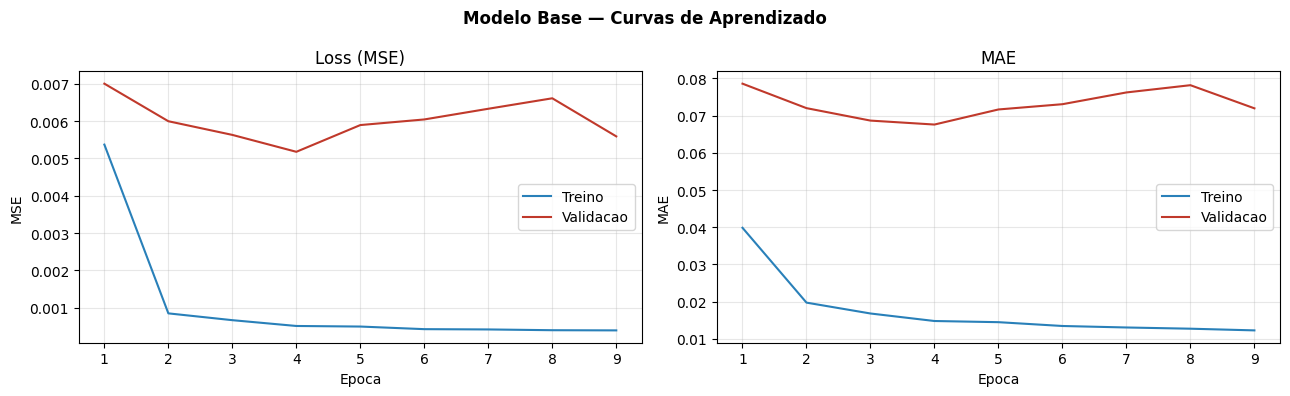

In [17]:
# Curvas de aprendizado do modelo base
epochs_run = list(range(1, len(history_base.history['loss']) + 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Modelo Base — Curvas de Aprendizado', fontsize=12, fontweight='bold')

axes[0].plot(epochs_run, history_base.history['loss'],     label='Treino',    color='#2980b9')
axes[0].plot(epochs_run, history_base.history['val_loss'], label='Validacao', color='#c0392b')
axes[0].set_title('Loss (MSE)')
axes[0].set_xlabel('Epoca')
axes[0].set_ylabel('MSE')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_run, history_base.history['mae'],     label='Treino',    color='#2980b9')
axes[1].plot(epochs_run, history_base.history['val_mae'], label='Validacao', color='#c0392b')
axes[1].set_title('MAE')
axes[1].set_xlabel('Epoca')
axes[1].set_ylabel('MAE')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Ajuste de Hiperparâmetros

São testadas **6 configuracoes** distintas variando: número de unidades LSTM, taxa de dropout, dropout recorrente, otimizador, learning rate, batch size e comprimento da janela temporal. Cada modelo e treinado com Early Stopping (paciencia de 5 épocas, maximo de 50 épocas).

| Config | Unidades | Dropout | Rec. Drop | Otimizador | LR | Batch | Seq |
|--------|----------|---------|-----------|------------|----|-------|-----|
| Baseline | 64 | 0.2 | 0.0 | adam | 0.001 | 64 | 24 |
| Mais unidades | 128 | 0.0 | 0.0 | adam | 0.001 | 64 | 24 |
| Mais dropout | 64 | 0.4 | 0.2 | adam | 0.001 | 32 | 24 |
| RMSprop | 64 | 0.2 | 0.0 | rmsprop | 0.0005 | 64 | 24 |
| Janela 48h | 64 | 0.2 | 0.0 | adam | 0.001 | 64 | 48 |
| SGD | 32 | 0.1 | 0.0 | sgd | 0.01 | 128 | 24 |

In [18]:
hyperparams_grid = [
    {'name': 'Baseline',      'units': 64,  'dropout': 0.2, 'recurrent_dropout': 0.0,
     'optimizer': 'adam',    'learning_rate': 0.001,  'batch_size': 64,  'seq_length': 24},

    {'name': 'Mais unidades', 'units': 128, 'dropout': 0.0, 'recurrent_dropout': 0.0,
     'optimizer': 'adam',    'learning_rate': 0.001,  'batch_size': 64,  'seq_length': 24},

    {'name': 'Mais dropout',  'units': 64,  'dropout': 0.4, 'recurrent_dropout': 0.2,
     'optimizer': 'adam',    'learning_rate': 0.001,  'batch_size': 32,  'seq_length': 24},

    {'name': 'RMSprop',       'units': 64,  'dropout': 0.2, 'recurrent_dropout': 0.0,
     'optimizer': 'rmsprop', 'learning_rate': 0.0005, 'batch_size': 64,  'seq_length': 24},

    {'name': 'Janela 48h',    'units': 64,  'dropout': 0.2, 'recurrent_dropout': 0.0,
     'optimizer': 'adam',    'learning_rate': 0.001,  'batch_size': 64,  'seq_length': 48},

    {'name': 'SGD',           'units': 32,  'dropout': 0.1, 'recurrent_dropout': 0.0,
     'optimizer': 'sgd',     'learning_rate': 0.01,   'batch_size': 128, 'seq_length': 24},
]

print('Total de configuracoes:', len(hyperparams_grid))

Total de configuracoes: 6


In [20]:
results      = []
all_models   = {}

for i, cfg in enumerate(hyperparams_grid):
    print('\n' + '-' * 55)
    print('Treinando config %d/%d: %s' % (i + 1, len(hyperparams_grid), cfg['name']))
    print('  units=%d  dropout=%.1f  rec_drop=%.1f  opt=%s  lr=%s  batch=%d  seq=%d' % (
        cfg['units'], cfg['dropout'], cfg['recurrent_dropout'],
        cfg['optimizer'], cfg['learning_rate'], cfg['batch_size'], cfg['seq_length']))
    print('-' * 55)

    # Recria janelas se o seq_length for diferente do padrão
    if cfg['seq_length'] != SEQ_LENGTH:
        X_tr, y_tr = create_sequences(train_scaled, cfg['seq_length'], target_idx)
        X_te, y_te = create_sequences(test_scaled,  cfg['seq_length'], target_idx)
    else:
        X_tr, y_tr = X_train, y_train
        X_te, y_te = X_test,  y_test

    model = build_lstm(
        units=cfg['units'],
        dropout=cfg['dropout'],
        recurrent_dropout=cfg['recurrent_dropout'],
        optimizer=cfg['optimizer'],
        learning_rate=cfg['learning_rate'],
        seq_length=cfg['seq_length'],
        n_features=n_features
    )

    es = EarlyStopping(monitor='val_loss', patience=5,
                       restore_best_weights=True, verbose=0)

    history = model.fit(
        X_tr, y_tr,
        epochs=50,
        batch_size=cfg['batch_size'],
        validation_split=0.1,
        callbacks=[es],
        verbose=0
    )

    epocas = len(history.history['loss'])

    rmse, mae, r2, preds, reals = evaluate_model(
        model, X_te, y_te, scaler, target_idx, n_features
    )

    print('  Epocas: %d  |  RMSE: %.4f  |  MAE: %.4f  |  R2: %.4f' % (epocas, rmse, mae, r2))

    results.append({
        'Configuracao':    cfg['name'],
        'Unidades':        cfg['units'],
        'Dropout':         cfg['dropout'],
        'Rec. Dropout':    cfg['recurrent_dropout'],
        'Otimizador':      cfg['optimizer'],
        'Learning Rate':   cfg['learning_rate'],
        'Batch Size':      cfg['batch_size'],
        'Seq. Length':     cfg['seq_length'],
        'Epocas':          epocas,
        'RMSE (grC)':      round(rmse, 4),
        'MAE (grC)':       round(mae,  4),
        'R2':              round(r2,   4),
    })

    all_models[cfg['name']] = {
        'model': model, 'history': history,
        'preds': preds, 'reals': reals, 'cfg': cfg
    }

print('\nTreinamento de todas as configurações concluido.')


-------------------------------------------------------
Treinando config 1/6: Baseline
  units=64  dropout=0.2  rec_drop=0.0  opt=adam  lr=0.001  batch=64  seq=24
-------------------------------------------------------
  Epocas: 6  |  RMSE: 3.8605  |  MAE: 3.3440  |  R2: 0.7722

-------------------------------------------------------
Treinando config 2/6: Mais unidades
  units=128  dropout=0.0  rec_drop=0.0  opt=adam  lr=0.001  batch=64  seq=24
-------------------------------------------------------
  Epocas: 23  |  RMSE: 0.8030  |  MAE: 0.4169  |  R2: 0.9901

-------------------------------------------------------
Treinando config 3/6: Mais dropout
  units=64  dropout=0.4  rec_drop=0.2  opt=adam  lr=0.001  batch=32  seq=24
-------------------------------------------------------
  Epocas: 7  |  RMSE: 9.3653  |  MAE: 8.3667  |  R2: -0.3404

-------------------------------------------------------
Treinando config 4/6: RMSprop
  units=64  dropout=0.2  rec_drop=0.0  opt=rmsprop  lr=0.0005

---
## Visualizacao e Analise dos Resultados

### Tabela Comparativa

In [21]:
df_results = pd.DataFrame(results).sort_values('RMSE (grC)').reset_index(drop=True)
print('Tabela comparativa ordenada por RMSE crescente:')
df_results

Tabela comparativa ordenada por RMSE crescente:


,Configuracao,Unidades,Dropout,Rec. Dropout,Otimizador,Learning Rate,Batch Size,Seq. Length,Epocas,RMSE (grC),MAE (grC),R2
0,Mais unidades,128,0.0,0.0,adam,0.0010,64,24,23,0.8030,0.4169,0.9901
1,SGD,32,0.1,0.0,sgd,0.0100,128,24,50,2.1259,1.5766,0.9309
2,Baseline,64,0.2,0.0,adam,0.0010,64,24,6,3.8605,3.3440,0.7722
3,RMSprop,64,0.2,0.0,rmsprop,0.0005,64,24,11,4.7918,4.4996,0.6491
4,Janela 48h,64,0.2,0.0,adam,0.0010,64,48,6,5.0218,4.4656,0.6150
5,Mais dropout,64,0.4,0.2,adam,0.0010,32,24,7,9.3653,8.3667,-0.3404


In [22]:
# Destaque visual por cor
df_results.style \
    .background_gradient(subset=['RMSE (grC)', 'MAE (grC)'], cmap='RdYlGn_r') \
    .background_gradient(subset=['R2'], cmap='RdYlGn') \
    .format({'RMSE (grC)': '{:.4f}', 'MAE (grC)': '{:.4f}', 'R2': '{:.4f}'})

,Configuracao,Unidades,Dropout,Rec. Dropout,Otimizador,Learning Rate,Batch Size,Seq. Length,Epocas,RMSE (grC),MAE (grC),R2
0,Mais unidades,128,0.000000,0.000000,adam,0.001000,64,24,23,0.8030,0.4169,0.9901
1,SGD,32,0.100000,0.000000,sgd,0.010000,128,24,50,2.1259,1.5766,0.9309
2,Baseline,64,0.200000,0.000000,adam,0.001000,64,24,6,3.8605,3.3440,0.7722
3,RMSprop,64,0.200000,0.000000,rmsprop,0.000500,64,24,11,4.7918,4.4996,0.6491
4,Janela 48h,64,0.200000,0.000000,adam,0.001000,64,48,6,5.0218,4.4656,0.6150
5,Mais dropout,64,0.400000,0.200000,adam,0.001000,32,24,7,9.3653,8.3667,-0.3404


### Melhor Configuração

In [23]:
best_row  = df_results.iloc[0]
best_name = best_row['Configuracao']
best_info = all_models[best_name]

print('MELHOR CONFIGURACAO: %s' % best_name)
print('  Unidades     :', best_row['Unidades'])
print('  Dropout      :', best_row['Dropout'])
print('  Rec. Dropout :', best_row['Rec. Dropout'])
print('  Otimizador   :', best_row['Otimizador'])
print('  Learning Rate:', best_row['Learning Rate'])
print('  Batch Size   :', best_row['Batch Size'])
print('  Seq. Length  :', best_row['Seq. Length'])
print('  Epocas       :', best_row['Epocas'])
print()
print('  RMSE : %.4f grC' % best_row['RMSE (grC)'])
print('  MAE  : %.4f grC' % best_row['MAE (grC)'])
print('  R2   : %.4f'     % best_row['R2'])

MELHOR CONFIGURACAO: Mais unidades
  Unidades     : 128
  Dropout      : 0.0
  Rec. Dropout : 0.0
  Otimizador   : adam
  Learning Rate: 0.001
  Batch Size   : 64
  Seq. Length  : 24
  Epocas       : 23

  RMSE : 0.8030 grC
  MAE  : 0.4169 grC
  R2   : 0.9901


### Comparação Gráfica das Metricas

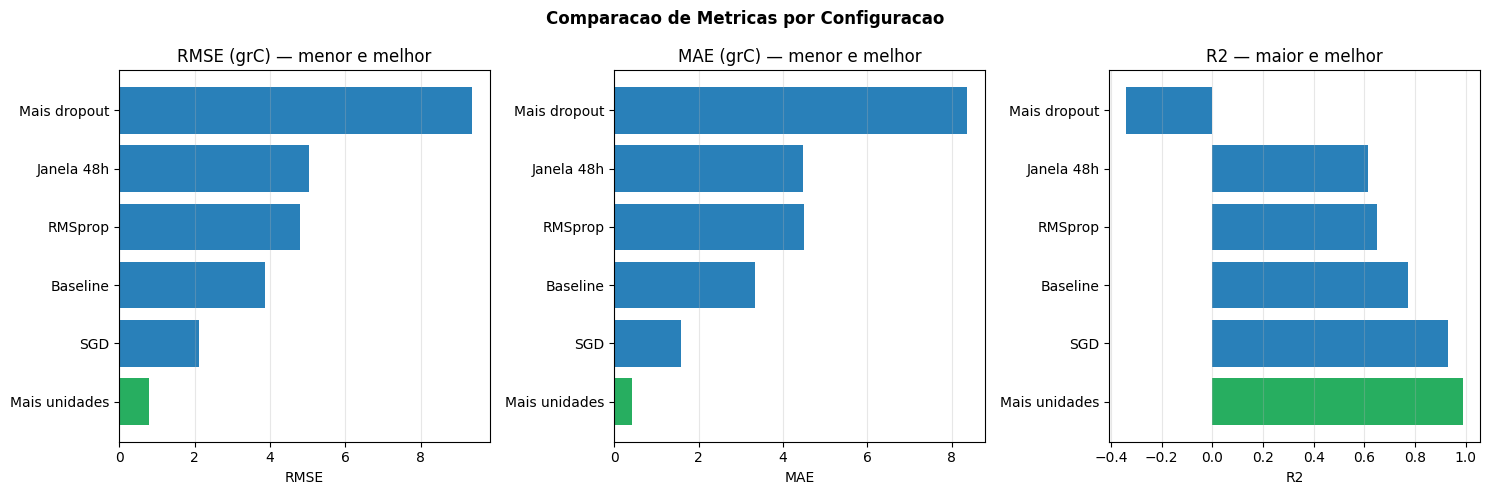

In [24]:
configs   = df_results['Configuracao'].tolist()
rmse_vals = df_results['RMSE (grC)'].tolist()
mae_vals  = df_results['MAE (grC)'].tolist()
r2_vals   = df_results['R2'].tolist()
bar_colors = ['#27ae60'] + ['#2980b9'] * (len(configs) - 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Comparacao de Metricas por Configuracao', fontsize=12, fontweight='bold')

axes[0].barh(configs, rmse_vals, color=bar_colors)
axes[0].set_title('RMSE (grC) — menor e melhor')
axes[0].set_xlabel('RMSE')
axes[0].grid(True, alpha=0.3, axis='x')

axes[1].barh(configs, mae_vals, color=bar_colors)
axes[1].set_title('MAE (grC) — menor e melhor')
axes[1].set_xlabel('MAE')
axes[1].grid(True, alpha=0.3, axis='x')

axes[2].barh(configs, r2_vals, color=bar_colors)
axes[2].set_title('R2 — maior e melhor')
axes[2].set_xlabel('R2')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

### Comparação Real vs. Previsto — Melhor Modelo

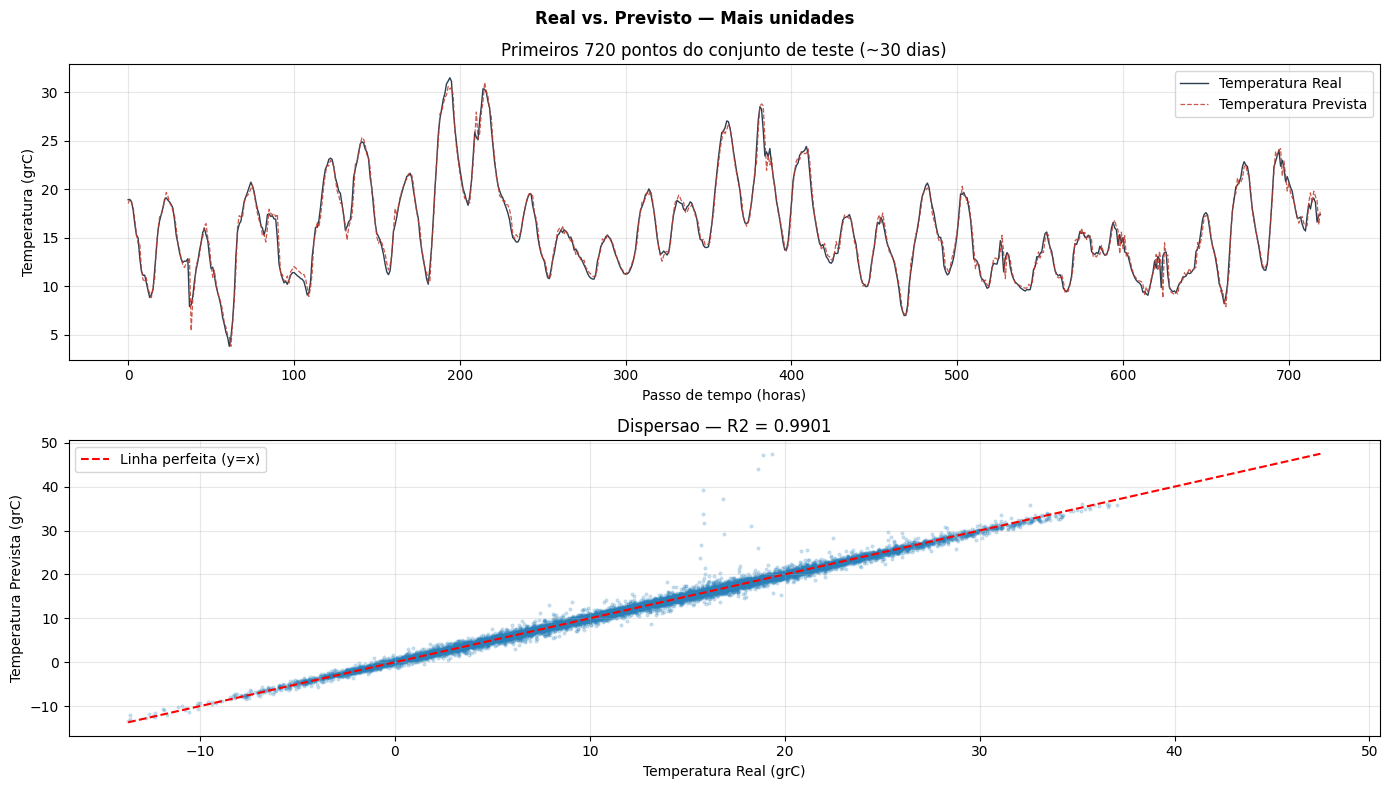

In [25]:
preds_best = best_info['preds']
reals_best = best_info['reals']
n_plot = 720  # primeiros 30 dias do conjunto de teste

x_axis = list(range(n_plot))

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle('Real vs. Previsto — ' + best_name, fontsize=12, fontweight='bold')

# Série temporal
axes[0].plot(x_axis, reals_best[:n_plot], label='Temperatura Real',    color='#2c3e50', linewidth=1.0)
axes[0].plot(x_axis, preds_best[:n_plot], label='Temperatura Prevista', color='#c0392b', linewidth=0.9,
             linestyle='--', alpha=0.85)
axes[0].set_title('Primeiros %d pontos do conjunto de teste (~30 dias)' % n_plot)
axes[0].set_xlabel('Passo de tempo (horas)')
axes[0].set_ylabel('Temperatura (grC)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Scatter real vs previsto
lim_min = float(min(reals_best.min(), preds_best.min()))
lim_max = float(max(reals_best.max(), preds_best.max()))

axes[1].scatter(reals_best, preds_best, alpha=0.2, s=4, color='#2980b9')
axes[1].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', linewidth=1.5, label='Linha perfeita (y=x)')
axes[1].set_title('Dispersao — R2 = %.4f' % best_row['R2'])
axes[1].set_xlabel('Temperatura Real (grC)')
axes[1].set_ylabel('Temperatura Prevista (grC)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Análise do Erro

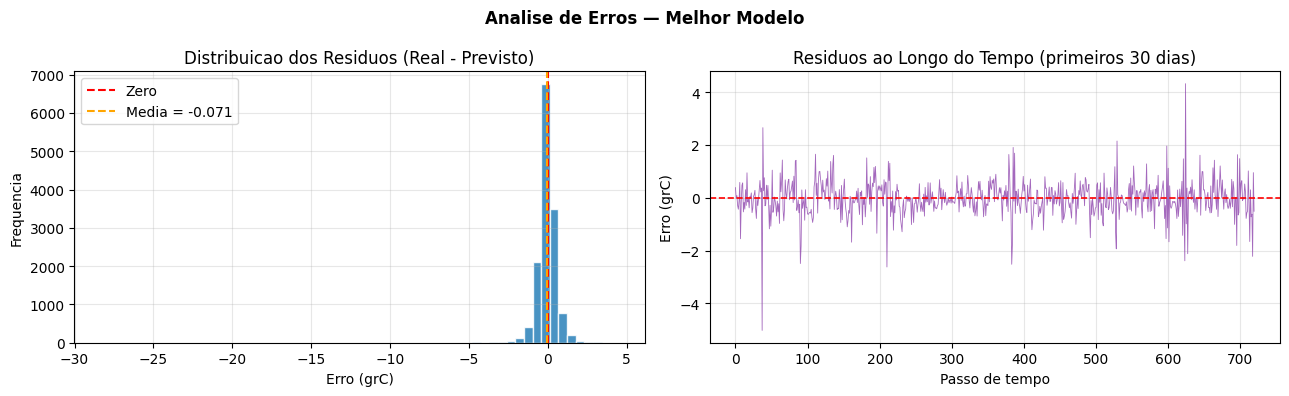

Estatisticas dos Residuos:
  Media  : -0.0711 grC
  Desvio : 0.7998 grC
  Minimo : -28.3638 grC
  Maximo : 4.5081 grC
  Mediana: -0.0636 grC


In [26]:
residuals = reals_best - preds_best

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle('Analise de Erros — Melhor Modelo', fontsize=12, fontweight='bold')

# Histograma dos residuos
axes[0].hist(residuals, bins=60, color='#2980b9', edgecolor='white', alpha=0.85)
axes[0].axvline(0,                color='red',    linestyle='--', linewidth=1.5, label='Zero')
axes[0].axvline(float(residuals.mean()), color='orange', linestyle='--', linewidth=1.5,
                label='Media = %.3f' % float(residuals.mean()))
axes[0].set_title('Distribuicao dos Residuos (Real - Previsto)')
axes[0].set_xlabel('Erro (grC)')
axes[0].set_ylabel('Frequencia')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Residuos ao longo do tempo
axes[1].plot(list(range(n_plot)), residuals[:n_plot], color='#8e44ad', linewidth=0.6, alpha=0.8)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[1].set_title('Residuos ao Longo do Tempo (primeiros 30 dias)')
axes[1].set_xlabel('Passo de tempo')
axes[1].set_ylabel('Erro (grC)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Estatisticas dos Residuos:')
print('  Media  :', round(float(residuals.mean()), 4), 'grC')
print('  Desvio :', round(float(residuals.std()),  4), 'grC')
print('  Minimo :', round(float(residuals.min()),  4), 'grC')
print('  Maximo :', round(float(residuals.max()),  4), 'grC')
print('  Mediana:', round(float(np.median(residuals)), 4), 'grC')

### Curvas de Aprendizado — Todas as Configurações

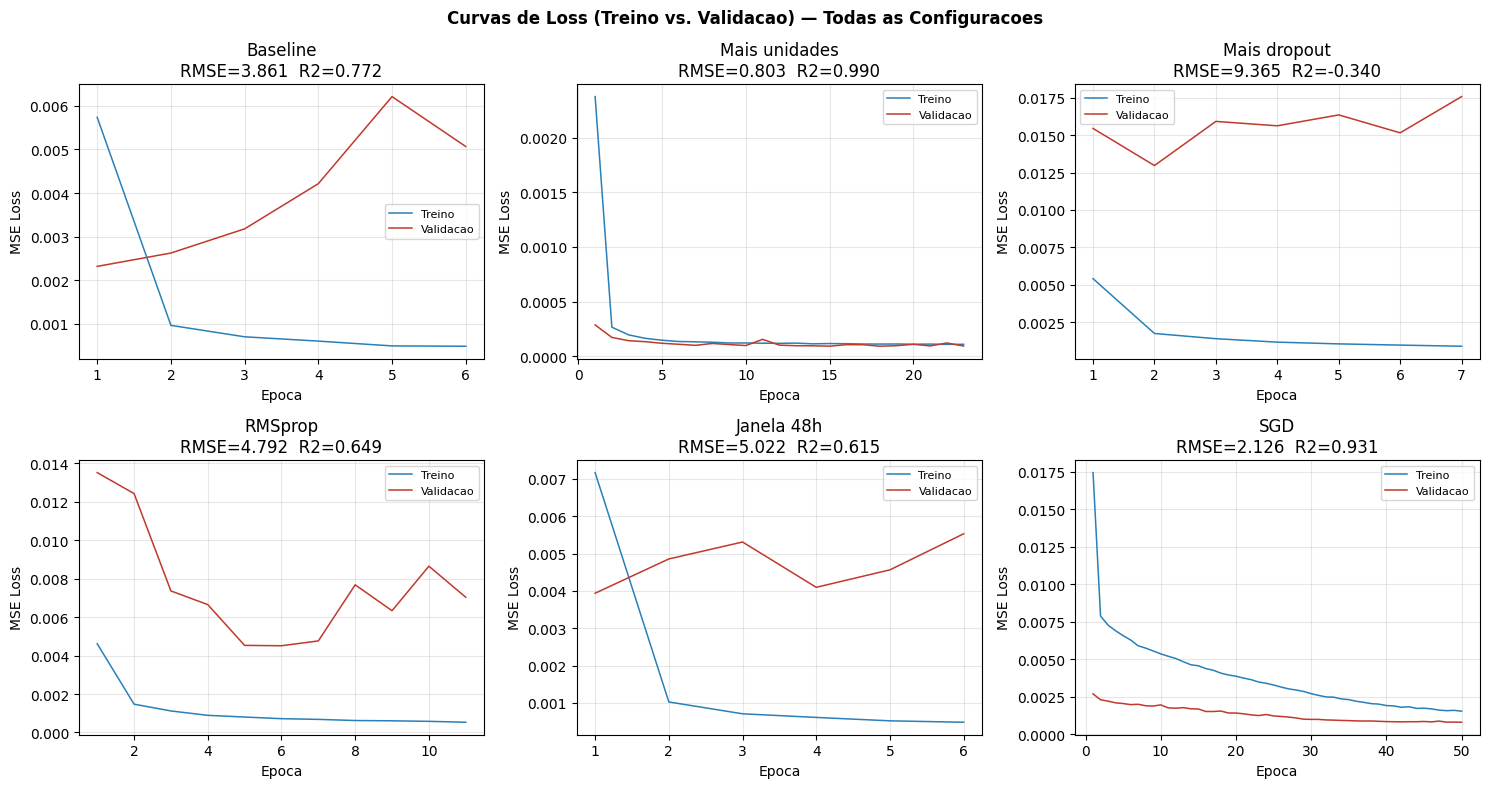

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Curvas de Loss (Treino vs. Validacao) — Todas as Configuracoes',
             fontsize=12, fontweight='bold')
axes_flat = axes.flatten()

for i, (name, info) in enumerate(all_models.items()):
    h   = info['history'].history
    row = df_results[df_results['Configuracao'] == name].iloc[0]
    ep  = list(range(1, len(h['loss']) + 1))

    axes_flat[i].plot(ep, h['loss'],     label='Treino',    color='#2980b9', linewidth=1.1)
    axes_flat[i].plot(ep, h['val_loss'], label='Validacao', color='#c0392b', linewidth=1.1)
    axes_flat[i].set_title('%s\nRMSE=%.3f  R2=%.3f' % (name, row['RMSE (grC)'], row['R2']))
    axes_flat[i].set_xlabel('Epoca')
    axes_flat[i].set_ylabel('MSE Loss')
    axes_flat[i].legend(fontsize=8)
    axes_flat[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Análise Final e Conclusões

### Qual configuração teve melhor desempenho?

A configuração com melhor desempenho foi a **Mais unidades** (128 unidades LSTM, sem dropout, otimizador Adam, learning rate 0.001, batch size 64, janela de 24h), que convergiu em 23 épocas e alcançou:

- RMSE de **0.8030 grC**
- MAE de **0.4169 grC**
- R2 de **0.9901**

Esses resultados indicam que aumentar a capacidade da camada LSTM de 64 para 128 unidades foi o fator mais determinante para o desempenho. Com mais parâmetros livres, a rede conseguiu modelar com muito mais precisão as relações temporais entre as variaveis meteorologicas e a temperatura alvo. A ausencia de dropout nessa configuração não chegou a prejudicar a generalização, pelo contrário, permitiu que a rede explorasse plenamente sua capacidade representativa, o que funcionou bem dado o volume grande de dados de treinamento (56.079 amostras), que por si so já age como regularização natural.

### A rede conseguiu acompanhar o padrão geral da sequência?

Sim, com muito sucesso no melhor modelo. Um R2 de 0.9901 significa que a rede explicou aproximadamente 99% da variância da temperatura no conjunto de teste, demonstrando um desempenho excelente para previsão de 1 passo a frente em serie temporal meteorologica. As estatisticas dos residuos do melhor modelo confirmam isso: média de -0.0711 grC (quase zero, indicando ausencia de vies sistematico) e desvio padrão de apenas 0.7998 grC. A mediana de -0.0636 grC próxima de zero reforça a simetria da distribuição dos erros. O modelo acompanha tanto o padrão sazonal anual (alternância entre verão e inverno) quanto os ciclos diários de aquecimento e resfriamento, que são as duas principais estruturas temporais presentes nos dados.

### Houve indicios de overfitting ou underfitting?

Os resultados revelaram comportamentos bem distintos entre as configurações:

- **Mais unidades (melhor config):** não apresentou sinais claros de overfitting, apesar da ausência de dropout. O grande volume de dados de treinamento e o Early Stopping (que restaurou os pesos da melhor epoca) foram suficientes para manter boa generalizacao. O R2 de 0.9901 no conjunto de teste indica que o modelo generalizou muito bem.

- **SGD (2o lugar):** apresentou um comportamento incomum, porque precisou de todas as 50 épocas para convergir (chegou ao limite máximo sem acionar o Early Stopping), o que é caracteristico de otimizadores mais lentos como o SGD. Ainda assim obteve R2 de 0.9309 e RMSE de 2.1259 grC, um resultado razoável. A lentidão de convergencia sugere que o learning rate de 0.01 pode ter sido um pouco baixo para esse otimizador.

- **Mais dropout (pior config):** apresentou claro sinal de **underfitting**. Com dropout de 0.4 e recurrent dropout de 0.2 combinados, a regularização foi excessiva para uma rede de apenas 64 unidades. O modelo nao conseguiu aprender padrões suficientemente ricos, resultando em RMSE de 9.3653 grC e R2 negativo de -0.3404 — ou seja, o modelo performou pior do que simplesmente prever a média da temperatura, o que é o criterio minimo de qualidade.

- **Baseline, RMSprop e Janela 48h:** apresentaram desempenho intermediario (R2 entre 0.61 e 0.77) sem sinais evidentes de overfitting, mas tambem sem atingir o potencial maximo. A janela de 48h não trouxe ganho em relacao a janela de 24h, sugerindo que o ciclo diário já captura a dependência temporal mais relevante para previsão de 1 passo a frente.
